# FlashPoint square detector: corrected edge + central-array position scan

The original sequential flow is retained: setup table → geometry → ROOT loading →
A + t₁ + t₂ + t₃ ExtraTrees reconstruction → summary → comparisons → local maps.
All matching job files are pooled **by event**, never by averaging per-file resolutions.

**Before running:** set `RUN` to `PlasticMuonTiming/run/BatchStudies_EdgeCenter`.
For example, `output_edge8_array8_1000/sipm_edge8_array8_1000_0.root`.
Install dependencies if needed: `%pip install numpy pandas matplotlib uproot scikit-learn`.

The default split holds out whole production jobs: 70% training, 15% validation,
15% test (rounded in job units). Geometry ranking and all scan plots use **validation**;
`test_*` columns provide a separate final check. Do not tune on test results. For a
confirmatory detector comparison, use fresh independent simulations after selection.
Different jobs must use independent simulation seeds; renamed duplicate simulations
cannot be made independent by splitting. File holdout estimates generalization to
new jobs from the same source distribution, not to unseen spatial regions.

Features contain only detected photon counts and relative measured times, never
truth positions, photon paths, source timing, or job/event IDs. Jitter is applied to
**every photon before sorting**, then the measured event-wide earliest time is removed.
Missing order statistics retain explicit masks; medians are fitted on training only.

The reported spread is σxy = sqrt((Var(dx)+Var(dy))/2), using population moments.
It excludes mean bias: inspect coordinate RMSE, radial quantiles, and local bias/RMSE
maps as well. Relative resolution is 100 σxy / `REFERENCE_LENGTH_MM`; geometry and
file names use the separate `LENGTH`. Scores are conditional on ≥1 detected photon;
all-event selection efficiency is reported separately.


In [1]:
# 0. Imports + global configuration
from pathlib import Path
import gc
import re
import warnings
import json
import hashlib
import platform
import sklearn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

from IPython.display import display
from sklearn.ensemble import ExtraTreesRegressor

SEED = 42

# Detector
LENGTH = 1000.0   # physical square side [mm], also used in file/directory names
REFERENCE_LENGTH_MM = 1000.0  # normalization only; never changes geometry
SIPM_ACTIVE_LENGTH_MM = 6.07
GEOMETRY_CONVENTION = "full_side"  # local DetectorConstruction.cc; see geometry note
assert LENGTH > 0 and REFERENCE_LENGTH_MM > 0
HALF = LENGTH / 2

# Same timing convention as the previous edge notebook
APPLY_TIMING_SMEARING = True
TIMING_SIGMA_PS = 300

# ExtraTrees settings: same basic choice as the previous notebook
TRAIN_FRAC = 0.70
VALIDATION_FRAC = 0.15
SPLIT_MODE = "file"  # "event" only for explicitly independent events/smoke tests
ALLOW_IMPLICIT_EVENT_IDS = False
TIME_BRANCH = "t_ns"  # raw photon time; change explicitly if your production differs
CHECK_DUPLICATE_FILES = True
ML_TRAIN_MAX = 100_000
N_ESTIMATORS = 300
MIN_SAMPLES_LEAF = 2
MAX_FEATURES = 0.8
MODEL_N_JOBS = -1

# Local map
MAP_GRID_N = 40
MIN_CELL = 10

# Diagnostic regions
CENTER_HALF = 0.25 * LENGTH   # |x|,|y| < 250 mm
EDGE_BAND = 0.15 * LENGTH     # outer 150 mm strip

# Input produced by submit_production.sh
RUN = Path("/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter")

OUT = RUN / "edge_center_position_study"
OUT.mkdir(parents=True, exist_ok=True)
MAP_OUT = OUT / "maps"
MAP_OUT.mkdir(parents=True, exist_ok=True)

# Optional quick debugging
MAX_FILES = None      # file holdout requires at least 3 nonempty jobs
SAVE_PREDICTIONS = False
VALIDATE_HIT_COUNTS = True

print("RUN =", RUN)
print("OUT =", OUT)


RUN = /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter
OUT = /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_EdgeCenter/edge_center_position_study


In [2]:
# 1. All submitted configurations
SETUPS = [
    # ~100 channels
    (20, 4),
    (15, 6),
    ( 8, 8),

    # intermediate
    (18, 6),
    (24, 4),
    (20, 6),
    ( 9, 9),
    (22, 6),
    (15, 8),

    # higher channel counts
    (24, 6),
    (18, 8),
    (10,10),
    (20, 8),
    (24, 8),
    (15,10),
    (11,11),
]

# Optional old Edge24 reference. Turn on only if the corresponding directory exists.
ADD_EDGE24_BASELINE = False
if ADD_EDGE24_BASELINE:
    SETUPS = [(24, 0)] + SETUPS

def setup_info(nedge, narray):
    perimeter = 4 + 4*nedge
    center = narray*narray
    total = perimeter + center

    # Edge-contact span follows the previous square notebook.
    edge_pitch = LENGTH/(nedge+1) if nedge > 0 else np.nan
    center_pitch = LENGTH/(narray+1) if narray > 0 else np.nan

    return dict(
        length_mm=LENGTH,
        reference_length_mm=REFERENCE_LENGTH_MM,
        edge=nedge,
        array=narray,
        perimeter_channels=perimeter,
        center_channels=center,
        total_channels=total,
        edge_pitch_mm=edge_pitch,
        center_pitch_mm=center_pitch,
        pitch_ratio=center_pitch/edge_pitch if narray > 0 else np.nan,
    )

setup_table = pd.DataFrame([setup_info(*s) for s in SETUPS])
display(setup_table.round(2))


,length_mm,reference_length_mm,edge,array,perimeter_channels,center_channels,total_channels,edge_pitch_mm,center_pitch_mm,pitch_ratio
0,1000.0,1000.0,20,4,84,16,100,47.62,200.00,4.20
1,1000.0,1000.0,15,6,64,36,100,62.50,142.86,2.29
2,1000.0,1000.0,8,8,36,64,100,111.11,111.11,1.00
3,1000.0,1000.0,18,6,76,36,112,52.63,142.86,2.71
4,1000.0,1000.0,24,4,100,16,116,40.00,200.00,5.00
5,1000.0,1000.0,20,6,84,36,120,47.62,142.86,3.00
6,1000.0,1000.0,9,9,40,81,121,100.00,100.00,1.00
7,1000.0,1000.0,22,6,92,36,128,43.48,142.86,3.29
8,1000.0,1000.0,15,8,64,64,128,62.50,111.11,1.78
9,1000.0,1000.0,24,6,100,36,136,40.00,142.86,3.57


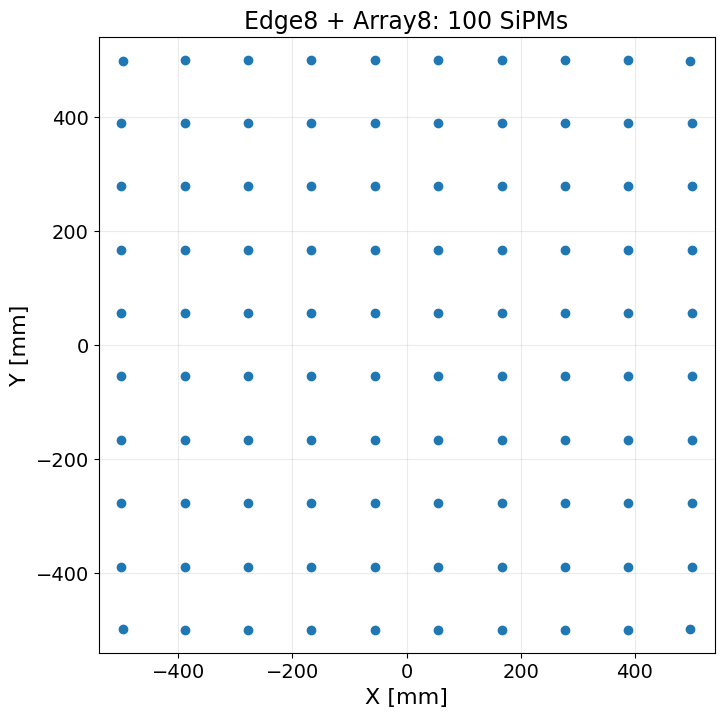

In [3]:
# 2. SiPM positions: same perimeter convention + new +Z center array

def get_pos(nedge, narray):
    edge = HALF - SIPM_ACTIVE_LENGTH_MM/(2*np.sqrt(2))
    pos = [
        [ edge, edge],
        [-edge, edge],
        [-edge,-edge],
        [ edge,-edge],
    ]

    if nedge:
        u = np.linspace(-HALF, HALF, nedge+2)[1:-1]
        pos += [[ x, HALF] for x in u]       # +Y
        pos += [[HALF,-y] for y in u]        # +X
        pos += [[-x,-HALF] for x in u]       # -Y
        pos += [[-HALF,y] for y in u]        # -X

    if narray:
        dx = LENGTH/(narray+1)
        dy = LENGTH/(narray+1)
        for iy in range(narray):
            y = -HALF + (iy+1)*dy
            for ix in range(narray):
                x = -HALF + (ix+1)*dx
                pos.append([x,y])

    return np.asarray(pos, float)

# Geometry sanity check for the matched 100-channel case
NEDGE_SHOW, NARRAY_SHOW = 8, 8
POS = get_pos(NEDGE_SHOW, NARRAY_SHOW)
expected = 4 + 4*NEDGE_SHOW + NARRAY_SHOW**2
assert len(POS) == expected

fig, ax = plt.subplots(figsize=(9,8))
ax.scatter(POS[:,0], POS[:,1])
ax.set(
    xlabel="X [mm]", ylabel="Y [mm]",
    title=f"Edge{NEDGE_SHOW} + Array{NARRAY_SHOW}: {expected} SiPMs",
    xlim=(-HALF-40, HALF+40), ylim=(-HALF-40, HALF+40),
    aspect="equal",
)
ax.tick_params(labelsize=14)
ax.xaxis.label.set_size(16)
ax.yaxis.label.set_size(16)
ax.title.set_size(17)
ax.grid(alpha=.25)
plt.show()


## 3. ROOT loading, geometry assumptions, and timing extraction

The checked local `PlasticMuonTiming_edit/src/DetectorConstruction.cc` uses corner
contact centers at ±(L/2 − 6.07/(2√2)) mm, and straight-edge contacts on ±L/2 with
pitch L/(nedge+1), ordered +Y, +X, −Y, −X after corners 0–3.
The central +Z array is shown as the original notebook's assumed row-major x-fastest
square grid, pitch L/(narray+1). **The available local simulation source has no center
array implementation, so its placement/order cannot be verified here.** Confirm this
against the production source before interpreting the geometry drawing/pitch.
ExtraTrees uses the numeric channel IDs directly and does not use these drawn
coordinates or a guessed photon propagation distance. No 2D time-of-flight correction
is imposed on the mixed edge/+Z geometry. Truth is the source (x,y); for inclined
tracks this is not necessarily the scintillator-plane intersection.

One ROOT file is read at a time, with exact branch/channel checks and local event-ID
mapping. `(file, event)` is the identity: event numbers may restart in every file.
Duplicate local IDs are rejected rather than merging ambiguous events. Raw `t_ns`
is required by default; `t_plot_ns` is never silently selected. All detected photons
must be represented in `hits`, including channels with fewer than three detections.
Zero-hit files/events and empty hit arrays are handled explicitly. Exact duplicate
ROOT files are rejected by checksum; independent simulation seeds remain a production
requirement. Numeric job sorting matches the screenshot (`…_2.root` before `…_10.root`).


In [4]:
# 3a. ROOT helpers
X_NAMES = ["source_x_mm", "x_source_mm", "source_x", "x_true_mm"]
Y_NAMES = ["source_y_mm", "y_source_mm", "source_y", "y_true_mm"]

def integer_ids(values, label):
    values = np.asarray(values)
    if values.ndim != 1 or not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError(f"{label} must contain finite integer IDs")
    return values.astype(np.int64)

def first_existing(keys, names):
    return next((x for x in names if x in set(keys)), None)

def read_hits(f, local_event_ids, nsipm):
    if "hits" not in f:
        raise KeyError("Missing hits tree")
    tree = f["hits"]
    required = ["event", "sipm", TIME_BRANCH]
    if not set(required).issubset(tree.keys()):
        raise KeyError(f"hits requires {required}; available: {list(tree.keys())}")
    # Individual branch reads work for both TTree and RNTuple containers.
    hev = integer_ids(tree["event"].array(library="np"), "hits.event")
    sipm = integer_ids(tree["sipm"].array(library="np"), "hits.sipm")
    tm = np.asarray(tree[TIME_BRANCH].array(library="np"), dtype=np.float64)
    row = pd.Index(local_event_ids).get_indexer(hev)
    if (row < 0).any():
        raise ValueError("Hit event ID absent from events tree")
    if ((sipm < 0) | (sipm >= nsipm)).any():
        raise ValueError("Out-of-range SiPM ID")
    if not np.isfinite(tm).all():
        raise ValueError("Non-finite photon time")
    return row, sipm, tm

def extract_t123(row, sipm, tm, nevents, nsipm, sigma_ps, rng):
    if sigma_ps < 0:
        raise ValueError("Timing sigma must be nonnegative")
    tm = np.asarray(tm, dtype=np.float64).copy()
    out = [np.full((nevents, nsipm), np.nan, dtype=np.float32) for _ in range(3)]
    if not len(tm):
        return tuple(out)
    if sigma_ps:
        tm += rng.normal(0.0, sigma_ps/1000.0, len(tm))
    t0 = np.full(nevents, np.inf)
    np.minimum.at(t0, row, tm)
    group = row*nsipm + sipm
    order = np.lexsort((tm, group))
    gs = group[order]
    starts = np.flatnonzero(np.r_[True, gs[1:] != gs[:-1]])
    ends = np.r_[starts[1:], len(gs)]
    dt = tm - t0[row]
    for k, target in enumerate(out):
        take = starts[starts+k < ends] + k
        target.ravel()[gs[take]] = dt[order[take]]
    return tuple(out)

def setup_directory(nedge, narray):
    tag = f"{LENGTH:g}"
    if narray == 0:
        return RUN / f"output_edge{nedge}_{tag}"
    return RUN / f"output_edge{nedge}_array{narray}_{tag}"

def discover_files(nedge, narray):
    indir = setup_directory(nedge, narray)
    stem = (f"sipm_edge{nedge}_array{narray}_{LENGTH:g}" if narray else
            f"sipm_edge{nedge}_{LENGTH:g}")
    pattern = re.compile(re.escape(stem) + r"_(\d+)\.root$")
    found = [(int(m.group(1)), p) for p in indir.glob(stem+"_*.root")
             if (m := pattern.fullmatch(p.name))]
    found.sort(key=lambda item: item[0])
    if MAX_FILES is not None:
        if MAX_FILES < 1:
            raise ValueError("MAX_FILES must be positive")
        found = found[:MAX_FILES]
    if not found:
        raise FileNotFoundError(f"No {stem}_<job>.root files in {indir}")
    if len({j for j, _ in found}) != len(found):
        raise ValueError("Duplicate numeric job IDs (e.g. _1 and _01)")
    return found

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(8*1024*1024), b""):
            digest.update(block)
    return digest.hexdigest()

def checked_num_entries(tree, file_label):
    raw = tree.num_entries
    # Some Geant4 ROOT files expose integral tree counts as floats.
    if not np.isfinite(raw) or raw < 0 or raw != int(raw):
        raise ValueError(f"{file_label}: invalid events.num_entries={raw!r}")
    return int(raw)

def load_setup(nedge, narray):
    nsipm = setup_info(nedge, narray)["total_channels"]
    blocks = {k: [] for k in ["truth", "A", "T1", "T2", "T3", "job", "event"]}
    audit, seen = [], set()
    for job, fname in discover_files(nedge, narray):
        digest = file_sha256(fname) if CHECK_DUPLICATE_FILES else None
        if digest is not None and digest in seen:
            raise ValueError(f"Duplicate file content: {fname}")
        seen.add(digest)
        with uproot.open(fname) as f:
            if "events" not in f:
                raise KeyError(f"{fname}: missing events tree")
            et = f["events"]
            keys = set(et.keys())
            xname, yname = first_existing(keys, X_NAMES), first_existing(keys, Y_NAMES)
            if xname is None or yname is None:
                raise KeyError(f"{fname}: missing truth X/Y branches")
            amp_names = [f"n_detected_sipm{i}" for i in range(nsipm)]
            actual = {k for k in keys if re.fullmatch(r"n_detected_sipm\d+", k)}
            if actual != set(amp_names):
                raise ValueError(f"{fname.name}: expected exactly {nsipm} detected-count channels; "
                                 f"missing={set(amp_names)-actual}, extra={actual-set(amp_names)}")
            n = checked_num_entries(et, fname.name)
            if "event" not in keys and not ALLOW_IMPLICIT_EVENT_IDS:
                raise KeyError("events.event absent; implicit row IDs require explicit opt-in")
            local = integer_ids(et["event"].array(library="np") if "event" in keys else np.arange(n),
                                "events.event")
            if len(local) != n:
                raise ValueError(f"{fname.name}: event branch length disagrees with tree entry count")
            if len(np.unique(local)) != n:
                raise ValueError(f"{fname.name}: duplicate local event IDs; need an additional run/worker key")
            truth = np.column_stack([et[k].array(library="np") for k in [xname, yname]]).astype(float)
            A = np.column_stack([et[k].array(library="np") for k in amp_names])
            if not np.isfinite(A).all() or (A < 0).any() or not np.equal(A, np.floor(A)).all():
                raise ValueError(f"{fname.name}: invalid photon counts")
            row, sipm, tm = read_hits(f, local, nsipm)
            if VALIDATE_HIT_COUNTS:
                hc = np.bincount(row*nsipm+sipm, minlength=n*nsipm).reshape(n, nsipm)
                if not np.array_equal(A, hc):
                    raise ValueError(f"{fname.name}: hit counts disagree with event amplitudes")
            # A stable RNG per configuration/job: adding another file does not change this job's jitter.
            rng = np.random.default_rng(np.random.SeedSequence([SEED, nedge, narray, job, 100]))
            times = extract_t123(row, sipm, tm, n, nsipm,
                                TIMING_SIGMA_PS if APPLY_TIMING_SMEARING else 0, rng)
            physical = np.isfinite(truth).all(axis=1) & (np.abs(truth) <= HALF+1e-6).all(axis=1)
            detected = A.sum(axis=1) > 0
            good = physical & detected
            audit.append(dict(file=str(fname.resolve()), job=job, sha256=digest, events=n,
                              valid_truth=int(physical.sum()), zero_hit=int((physical & ~detected).sum()),
                              selected=int(good.sum())))
            values = dict(truth=truth, A=A.astype(np.float32), T1=times[0], T2=times[1], T3=times[2],
                          job=np.full(n, job, dtype=np.int64), event=local)
            for k, v in values.items():
                blocks[k].append(v[good])
        print(f"  {fname.name}: events={n:,}, selected={good.sum():,}")
    data = {k: np.concatenate(v) for k, v in blocks.items()}
    if not len(data["truth"]):
        raise ValueError("No usable detected events in setup")
    data["audit"] = pd.DataFrame(audit)
    return data


In [5]:
# 4. Metrics + local position-resolution map

def sigma_xy_from_residual(d):
    if len(d) < 2:
        return np.nan
    sx = np.std(d[:,0])
    sy = np.std(d[:,1])
    return np.sqrt((sx*sx + sy*sy)/2)

def resolution_metrics(truth, pred):
    valid = np.isfinite(pred).all(axis=1) & np.isfinite(truth).all(axis=1)
    t = truth[valid]
    p = pred[valid]
    d = p - t

    if not len(d):
        raise ValueError("No finite predictions to score")
    dx, dy = d[:,0], d[:,1]
    r = np.hypot(dx, dy)

    sx, sy = np.std(dx), np.std(dy)
    sxy = np.sqrt((sx*sx + sy*sy)/2)

    center = (np.abs(t[:,0]) < CENTER_HALF) & (np.abs(t[:,1]) < CENTER_HALF)
    outer = np.maximum(np.abs(t[:,0]), np.abs(t[:,1])) > (HALF - EDGE_BAND)

    return dict(
        N=len(t),
        N_center=int(((np.abs(t) < CENTER_HALF).all(axis=1)).sum()),
        N_outer=int((np.max(np.abs(t), axis=1) > HALF-EDGE_BAND).sum()),
        coverage=valid.mean(),
        bias_x_mm=np.mean(dx),
        bias_y_mm=np.mean(dy),
        sigma_x_mm=sx,
        sigma_y_mm=sy,
        sigma_xy_mm=sxy,
        relative_sigma_xy_pct=100*sxy/REFERENCE_LENGTH_MM,
        RMSE_xy_mm=np.sqrt(np.mean(d*d)),
        radial_RMSE_mm=np.sqrt(np.mean(np.sum(d*d, axis=1))),
        R68_mm=np.quantile(r, .68),
        R90_mm=np.quantile(r, .90),
        sigma_xy_center_mm=sigma_xy_from_residual(d[center]),
        sigma_xy_outer_mm=sigma_xy_from_residual(d[outer]),
    )

def local_sigma_map(truth, pred, grid_n=MAP_GRID_N, min_cell=MIN_CELL):
    valid = np.isfinite(pred).all(axis=1) & np.isfinite(truth).all(axis=1)
    t = truth[valid]
    d = pred[valid] - t

    edges = np.linspace(-HALF, HALF, grid_n+1)
    ix = np.clip(np.searchsorted(edges, t[:,0], side="right") - 1, 0, grid_n-1)
    iy = np.clip(np.searchsorted(edges, t[:,1], side="right") - 1, 0, grid_n-1)
    gid = iy*grid_n + ix
    ncell = grid_n*grid_n

    count = np.bincount(gid, minlength=ncell)

    sums = np.column_stack([
        np.bincount(gid, weights=d[:,j], minlength=ncell)
        for j in range(2)
    ])
    sums2 = np.column_stack([
        np.bincount(gid, weights=d[:,j]**2, minlength=ncell)
        for j in range(2)
    ])

    mean = np.divide(
        sums, count[:,None],
        out=np.zeros_like(sums),
        where=count[:,None] > 0
    )
    second = np.divide(
        sums2, count[:,None],
        out=np.zeros_like(sums2),
        where=count[:,None] > 0
    )

    var = np.maximum(second - mean**2, 0)
    sxy = np.sqrt(var.mean(axis=1))
    sxy[count < min_cell] = np.nan

    shape = (grid_n, grid_n)
    rmse = np.sqrt(second.mean(axis=1))
    bias = np.linalg.norm(mean, axis=1)
    rmse[count < min_cell] = np.nan
    bias[count < min_cell] = np.nan
    return sxy.reshape(shape), count.reshape(shape), rmse.reshape(shape), bias.reshape(shape)

def save_local_map(nedge, narray, sxy):
    fig, ax = plt.subplots(figsize=(9,8))
    im = ax.imshow(
        sxy, origin="lower",
        extent=(-HALF, HALF, -HALF, HALF),
        aspect="equal", vmin=0
    )

    centers = np.linspace(
        -HALF + LENGTH/(2*MAP_GRID_N),
         HALF - LENGTH/(2*MAP_GRID_N),
         MAP_GRID_N
    )
    X, Y = np.meshgrid(centers, centers)

    finite = sxy[np.isfinite(sxy)]
    if len(finite) and finite.min() < 10 < finite.max():
        cs = ax.contour(X, Y, sxy, levels=[10], linewidths=2)
        ax.clabel(cs, fmt="10 mm", fontsize=12)

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\sigma_{xy}$ [mm]", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

    ax.set(
        xlabel="Truth X [mm]",
        ylabel="Truth Y [mm]",
        title=f"Validation: Edge{nedge} + Array{narray}"
    )
    ax.tick_params(labelsize=14)
    ax.xaxis.label.set_size(16)
    ax.yaxis.label.set_size(16)
    ax.title.set_size(17)

    plt.tight_layout()
    fname = MAP_OUT / f"resolution_map_edge{nedge}_array{narray}.png"
    plt.savefig(fname, dpi=180, bbox_inches="tight")
    plt.close(fig)

    return fname


In [6]:
# 5. Training-only preprocessing and disjoint train/validation/test samples

def training_medians(X):
    med = np.zeros(X.shape[1], dtype=np.float32)
    finite = np.isfinite(X)
    columns = finite.any(axis=0)
    med[columns] = np.nanmedian(np.where(finite[:, columns], X[:, columns], np.nan), axis=0)
    return med

def build_features(A, T1, T2, T3, indices):
    # Slice first: chunked inference must not recompute a full-dataset normalized copy.
    a = A[indices].astype(np.float32, copy=False)
    ntot = a.sum(axis=1, dtype=np.float64)
    fractions = np.divide(a, ntot[:, None], out=np.zeros_like(a), where=ntot[:, None] > 0)
    times = [t[indices] for t in (T1, T2, T3)]
    return np.hstack([fractions, np.log1p(ntot)[:, None], *times,
                      *[np.isfinite(t).astype(np.float32) for t in times]]).astype(np.float32)

def split_indices(data):
    if not (0 < TRAIN_FRAC < 1 and 0 < VALIDATION_FRAC < 1-TRAIN_FRAC):
        raise ValueError("Need positive train/validation/test fractions")
    if SPLIT_MODE not in {"file", "event"}:
        raise ValueError("SPLIT_MODE must be file or event")
    units = np.unique(data["job"]) if SPLIT_MODE == "file" else np.arange(len(data["truth"]))
    if len(units) < 3:
        raise ValueError("Need at least 3 nonempty split units; do not silently fall back to event splitting")
    rng = np.random.default_rng(SEED)
    shuffled = rng.permutation(units)
    nval = max(1, int(round(VALIDATION_FRAC*len(units))))
    ntest = max(1, int(round((1-TRAIN_FRAC-VALIDATION_FRAC)*len(units))))
    ntrain = len(units)-nval-ntest
    if ntrain < 1:
        raise ValueError("Too few units for requested fractions")
    groups = [shuffled[:ntrain], shuffled[ntrain:ntrain+nval], shuffled[ntrain+nval:]]
    if SPLIT_MODE == "file":
        parts = [np.flatnonzero(np.isin(data["job"], g)) for g in groups]
    else:
        warnings.warn("Event split assumes independent events; jobs may appear in all three samples")
        parts = groups
    assert not (set(parts[0]) & set(parts[1]) or set(parts[0]) & set(parts[2]) or set(parts[1]) & set(parts[2]))
    return parts

def reconstruct_setup(nedge, narray):
    info = setup_info(nedge, narray)
    print(f"\nEdge{nedge} + Array{narray}: {info['total_channels']} channels")
    data = load_setup(nedge, narray)
    truth, A, T1, T2, T3 = [data[k] for k in ["truth", "A", "T1", "T2", "T3"]]
    itr, iva, ite = split_indices(data)
    rng = np.random.default_rng(SEED+1)
    itr_ml = itr if ML_TRAIN_MAX is None or len(itr) <= ML_TRAIN_MAX else rng.choice(itr, ML_TRAIN_MAX, replace=False)
    if len(itr_ml) < 2:
        raise ValueError("Insufficient training events")
    Xtr = build_features(A, T1, T2, T3, itr_ml)
    med = training_medians(Xtr)
    Xtr = np.where(np.isfinite(Xtr), Xtr, med)
    model = ExtraTreesRegressor(n_estimators=N_ESTIMATORS, min_samples_leaf=MIN_SAMPLES_LEAF,
                               max_features=MAX_FEATURES, n_jobs=MODEL_N_JOBS, random_state=SEED)
    model.fit(Xtr, truth[itr_ml])
    del Xtr
    def predict(ids):
        pred = np.empty((len(ids), 2), dtype=np.float32)
        for start in range(0, len(ids), 5000):
            ix = ids[start:start+5000]
            X = build_features(A, T1, T2, T3, ix)
            pred[start:start+len(ix)] = model.predict(np.where(np.isfinite(X), X, med))
        return pred
    val_pred, test_pred = predict(iva), predict(ite)
    met = resolution_metrics(truth[iva], val_pred)
    test_met = resolution_metrics(truth[ite], test_pred)
    sxy, count, rmse, bias = local_sigma_map(truth[iva], val_pred)
    tag = f"edge{nedge}_array{narray}"
    map_file = save_local_map(nedge, narray, sxy)
    np.savez_compressed(MAP_OUT/f"{tag}_validation_maps.npz", sigma_xy=sxy, count=count,
                        coordinate_rmse=rmse, radial_bias=bias,
                        bin_edges=np.linspace(-HALF, HALF, MAP_GRID_N+1))
    # Preserve provenance and split assignment even when large predictions are not saved.
    split = np.full(len(truth), "train", dtype="U10")
    split[iva], split[ite] = "validation", "test"
    used = np.zeros(len(truth), dtype=bool)
    used[itr_ml] = True
    np.savez_compressed(OUT/f"{tag}_split.npz", job=data["job"], event=data["event"],
                        split=split, used_for_fit=used, training_medians=med)
    data["audit"].to_csv(OUT/f"{tag}_files.csv", index=False)
    per_job = []
    for label, ids, pred in [("validation", iva, val_pred), ("test", ite, test_pred)]:
        for job in np.unique(data["job"][ids]):
            mask = data["job"][ids] == job
            per_job.append(dict(split=label, job=int(job), **resolution_metrics(truth[ids][mask], pred[mask])))
        if SAVE_PREDICTIONS:
            np.savez_compressed(OUT/f"pred_{tag}_{label}.npz", truth=truth[ids], pred=pred,
                                job=data["job"][ids], event=data["event"][ids])
    pd.DataFrame(per_job).to_csv(OUT/f"{tag}_per_job_metrics.csv", index=False)
    audit = data["audit"]
    result = {**info, **met, **{f"test_{k}": v for k, v in test_met.items()},
              "ranking_split": "validation", "split_mode": SPLIT_MODE,
              "events_generated": int(audit.events.sum()), "events_valid_truth": int(audit.valid_truth.sum()),
              "events_zero_hit": int(audit.zero_hit.sum()), "events_total": len(truth),
              "selection_efficiency": len(truth)/int(audit.events.sum()),
              "detection_efficiency_valid_truth": len(truth)/int(audit.valid_truth.sum()),
              "files_loaded": len(audit), "events_train": len(itr), "events_train_ml": len(itr_ml),
              "events_validation": len(iva), "events_test": len(ite),
              "train_jobs": ','.join(map(str, np.unique(data['job'][itr]))),
              "validation_jobs": ','.join(map(str, np.unique(data['job'][iva]))),
              "test_jobs": ','.join(map(str, np.unique(data['job'][ite]))),
              "mean_detected_photons": float(A.sum(axis=1).mean()), "map_file": str(map_file)}
    print(f"  validation σxy={met['sigma_xy_mm']:.2f} mm; test σxy={test_met['sigma_xy_mm']:.2f} mm")
    del model, data, truth, A, T1, T2, T3, val_pred, test_pred
    gc.collect()
    return result, sxy


## 6. Run the full scan

Each configuration is reconstructed and released before the next one. Missing or
invalid productions are recorded in `failed_setups.csv`. The notebook does not treat
an unsuccessful scan as a successful zero-row result; downstream plots safely skip it.
Summary values without a prefix refer to validation. `test_*` values are held-out checks.
Per-job diagnostics are saved, but pooled residuals determine the setup's resolution.


In [7]:
# 6. Process all configurations
metadata = {k: globals()[k] for k in ["SEED", "LENGTH", "REFERENCE_LENGTH_MM", "SIPM_ACTIVE_LENGTH_MM",
    "GEOMETRY_CONVENTION", "TIME_BRANCH", "APPLY_TIMING_SMEARING", "TIMING_SIGMA_PS", "SPLIT_MODE",
    "TRAIN_FRAC", "VALIDATION_FRAC", "ML_TRAIN_MAX", "N_ESTIMATORS", "MIN_SAMPLES_LEAF",
    "MAX_FEATURES", "MAX_FILES", "VALIDATE_HIT_COUNTS", "CHECK_DUPLICATE_FILES", "MAP_GRID_N", "MIN_CELL"]}
metadata.update(run=str(RUN), setups=SETUPS, python=platform.python_version(),
                numpy=np.__version__, sklearn=sklearn.__version__, uproot=uproot.__version__)
(OUT / "analysis_config.json").write_text(json.dumps(metadata, indent=2))
results = []
# Reset only this scan's summaries so an all-failed rerun cannot show stale results.
pd.DataFrame().to_csv(OUT / "edge_center_position_summary_partial.csv", index=False)
maps = {}
failed = []

for nedge, narray in SETUPS:
    try:
        result, sxy_map = reconstruct_setup(nedge, narray)
        results.append(result)
        maps[(nedge, narray)] = sxy_map

        # Save incremental summary so a long scan is not lost.
        pd.DataFrame(results).to_csv(
            OUT / "edge_center_position_summary_partial.csv",
            index=False
        )

    except Exception as exc:
        import traceback
        detail = traceback.format_exc()
        failed.append((nedge, narray, repr(exc), detail))
        warnings.warn(f"Edge{nedge} Array{narray} failed: {exc}")
        print(detail)


summary = pd.DataFrame(results)

if len(summary):
    summary = summary.sort_values(
        ["sigma_xy_mm", "total_channels"]
    ).reset_index(drop=True)

    summary.to_csv(
        OUT / "edge_center_position_summary.csv",
        index=False
    )

summary.to_csv(OUT / "edge_center_position_summary.csv", index=False)
display(summary.round(3))

if failed:
    print("\nFailed / missing setups:")
    display(pd.DataFrame(failed, columns=["edge","array","error","traceback"]))

pd.DataFrame(failed, columns=["edge", "array", "error", "traceback"]).to_csv(OUT / "failed_setups.csv", index=False)
if summary.empty:
    warnings.warn("No setup completed. Check RUN, file names, and failed_setups.csv.")



Edge20 + Array4: 100 channels
  sipm_edge20_array4_1000_0.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_1.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_2.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_3.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_4.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_5.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_6.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_7.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_8.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_9.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_10.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_11.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_12.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_13.root: events=10,000, selected=10,000
  sipm_edge20_array4_1000_14.root: events=10,000, selec

,length_mm,reference_length_mm,edge,array,perimeter_channels,center_channels,total_channels,edge_pitch_mm,center_pitch_mm,pitch_ratio,...,files_loaded,events_train,events_train_ml,events_validation,events_test,train_jobs,validation_jobs,test_jobs,mean_detected_photons,map_file
0,1000.0,1000.0,15,10,64,100,164,62.500,90.909,1.455,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",1142.556,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
1,1000.0,1000.0,24,8,100,64,164,40.000,111.111,2.778,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",1242.732,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
2,1000.0,1000.0,11,11,48,121,169,83.333,83.333,1.000,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",1125.597,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
3,1000.0,1000.0,20,8,84,64,148,47.619,111.111,2.333,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",1119.755,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
4,1000.0,1000.0,18,8,76,64,140,52.632,111.111,2.111,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",1055.569,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
5,1000.0,1000.0,10,10,44,100,144,90.909,90.909,1.000,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",983.396,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
6,1000.0,1000.0,15,8,64,64,128,62.500,111.111,1.778,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",958.467,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
7,1000.0,1000.0,24,6,100,36,136,40.000,142.857,3.571,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",1099.999,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
8,1000.0,1000.0,22,6,92,36,128,43.478,142.857,3.286,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",1037.248,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...
9,1000.0,1000.0,20,6,84,36,120,47.619,142.857,3.000,...,20,140000,100000,30000,30000,"0,3,5,6,7,9,10,11,12,14,15,16,18,19","2,4,17","1,8,13",974.869,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...


In [8]:
if not summary.empty:
    # 7. Compact ranking for the inclusive position-resolution optimization
    cols = [
        "edge", "array",
        "perimeter_channels", "center_channels", "total_channels",
        "edge_pitch_mm", "center_pitch_mm", "pitch_ratio",
        "sigma_xy_mm", "relative_sigma_xy_pct",
        "sigma_xy_center_mm", "sigma_xy_outer_mm",
        "R68_mm", "R90_mm",
    ]

    ranking = summary[cols].sort_values("sigma_xy_mm").reset_index(drop=True)
    display(ranking.round(3))

    if len(ranking):
        best = ranking.iloc[0]
        print(
            f"Best validation sigma_xy: Edge{int(best.edge)} + Array{int(best['array'])} "
            f"= {best.sigma_xy_mm:.2f} mm "
            f"({best.relative_sigma_xy_pct:.3f}%), "
            f"N={int(best.total_channels)} channels"
        )
else:
    print("No successful setups to display.")


,edge,array,perimeter_channels,center_channels,total_channels,edge_pitch_mm,center_pitch_mm,pitch_ratio,sigma_xy_mm,relative_sigma_xy_pct,sigma_xy_center_mm,sigma_xy_outer_mm,R68_mm,R90_mm
0,15,10,64,100,164,62.500,90.909,1.455,11.180,1.118,10.185,12.367,15.597,23.949
1,24,8,100,64,164,40.000,111.111,2.778,11.297,1.130,11.311,11.833,16.112,23.692
2,11,11,48,121,169,83.333,83.333,1.000,11.408,1.141,9.584,13.003,15.402,24.644
3,20,8,84,64,148,47.619,111.111,2.333,11.631,1.163,11.424,12.350,16.580,24.464
4,18,8,76,64,140,52.632,111.111,2.111,11.813,1.181,11.590,12.535,16.884,25.055
5,10,10,44,100,144,90.909,90.909,1.000,12.249,1.225,10.293,14.012,16.648,26.143
6,15,8,64,64,128,62.500,111.111,1.778,12.310,1.231,11.660,13.293,17.457,26.112
7,24,6,100,36,136,40.000,142.857,3.571,12.423,1.242,13.277,12.399,17.839,26.237
8,22,6,92,36,128,43.478,142.857,3.286,12.688,1.269,13.325,12.802,18.164,26.679
9,20,6,84,36,120,47.619,142.857,3.000,12.894,1.289,13.553,13.050,18.482,27.173


Best validation sigma_xy: Edge15 + Array10 = 11.18 mm (1.118%), N=164 channels


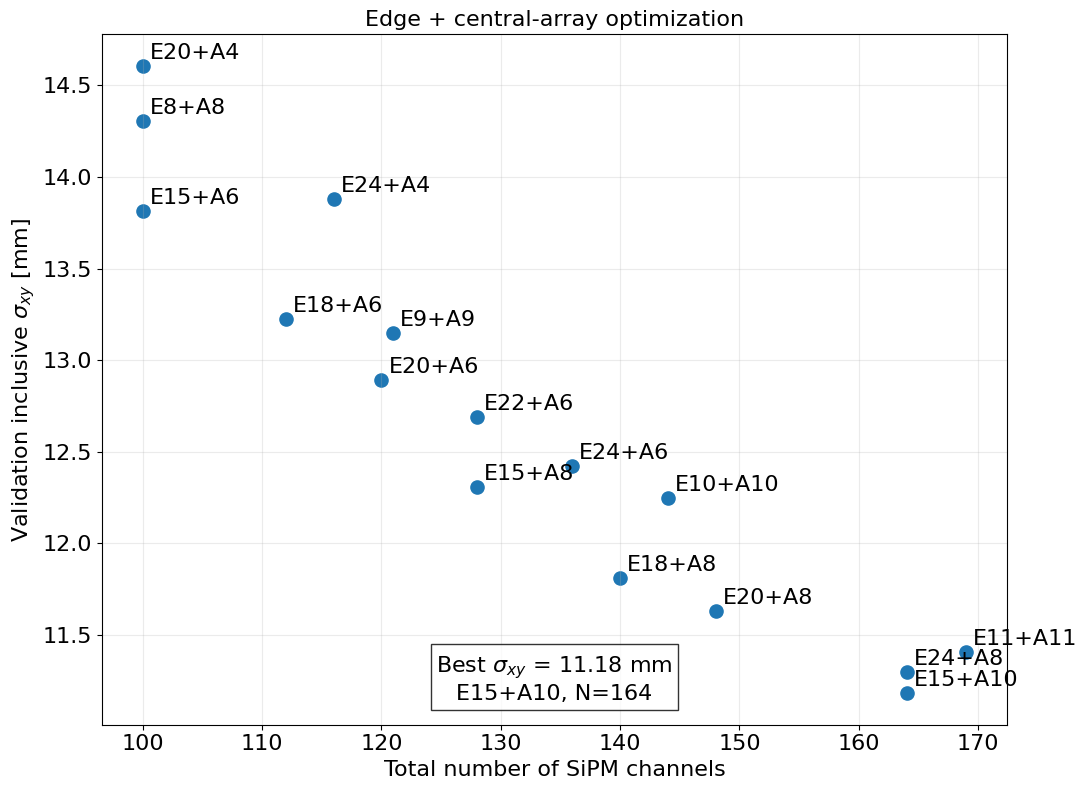

In [18]:
if not summary.empty:
    fig, ax = plt.subplots(figsize=(11,8))

    ax.scatter(summary.total_channels, summary.sigma_xy_mm, s=90)

    for _, r in summary.iterrows():
        ax.annotate(f"E{int(r.edge)}+A{int(r['array'])}",
                    (r.total_channels, r.sigma_xy_mm),
                    xytext=(5,5), textcoords="offset points", fontsize=16)

    ax.set(xlabel="Total number of SiPM channels",
           ylabel=r"Validation inclusive $\sigma_{xy}$ [mm]",
           title="Edge + central-array optimization")
    ax.tick_params(labelsize=16)
    ax.xaxis.label.set_size(16); ax.yaxis.label.set_size(16); ax.title.set_size(16)
    ax.grid(alpha=.25)

    b = summary.loc[summary.sigma_xy_mm.idxmin()]
    txt = (rf"Best $\sigma_{{xy}}$ = {b.sigma_xy_mm:.2f} mm"
           f"\nE{int(b.edge)}+A{int(b['array'])}, N={int(b.total_channels)}")

    ax.text(.5, .03, txt, transform=ax.transAxes, ha="center", va="bottom",
            fontsize=16, bbox=dict(facecolor="white", alpha=.8))

    plt.tight_layout()
    plt.savefig(OUT/"sigma_xy_vs_total_channels.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No successful setups to display.")

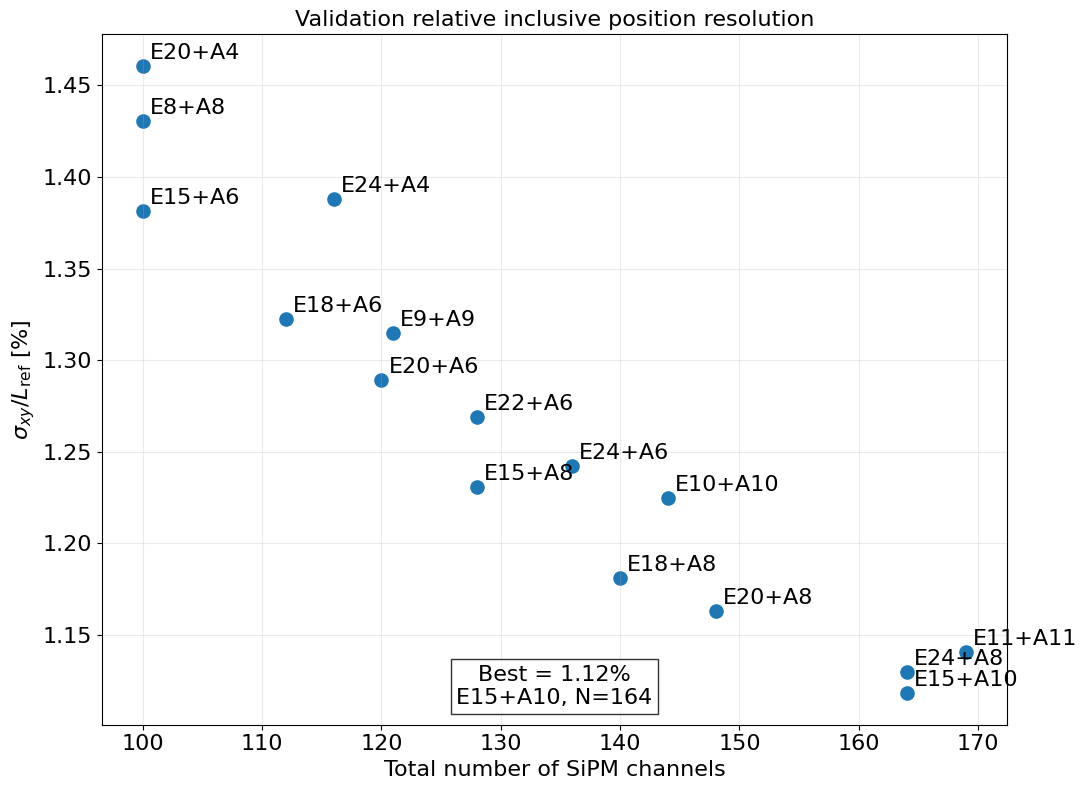

In [19]:
if not summary.empty:
    fig, ax = plt.subplots(figsize=(11,8))
    x, y = summary.total_channels, summary.relative_sigma_xy_pct

    ax.scatter(x, y, s=90)
    for _, r in summary.iterrows():
        ax.annotate(f"E{int(r.edge)}+A{int(r['array'])}",
                    (r.total_channels,r.relative_sigma_xy_pct),
                    xytext=(5,5), textcoords="offset points", fontsize=16)

    ax.set(xlabel="Total number of SiPM channels",
           ylabel=r"$\sigma_{xy}/L_{\rm ref}$ [%]",
           title="Validation relative inclusive position resolution")
    ax.tick_params(labelsize=16); ax.grid(alpha=.25)
    plt.setp([ax.xaxis.label, ax.yaxis.label, ax.title], fontsize=16)

    b = summary.loc[y.idxmin()]
    ax.text(.5,.03, f"Best = {b.relative_sigma_xy_pct:.2f}%\n"
                    f"E{int(b.edge)}+A{int(b['array'])}, N={int(b.total_channels)}",
            transform=ax.transAxes, ha="center", fontsize=16,
            bbox=dict(facecolor="white", alpha=.8))

    plt.tight_layout()
    plt.savefig(OUT/"relative_sigma_xy_vs_total_channels.png", dpi=180)
    plt.show()
else:
    print("No successful setups to display.")

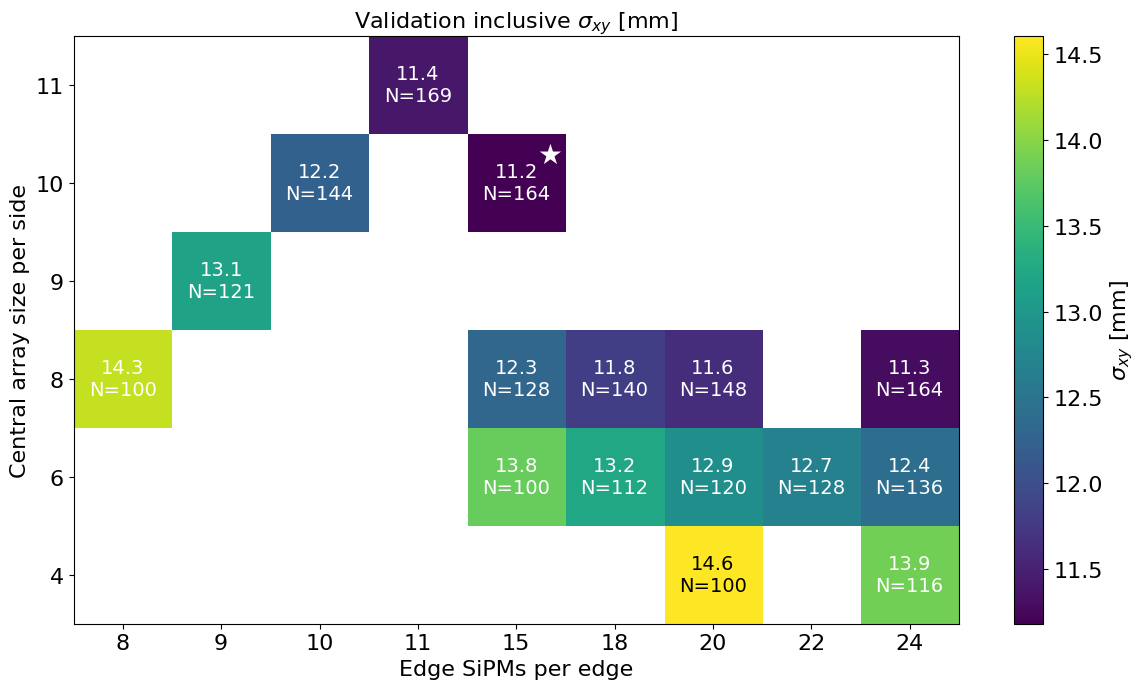

In [22]:
if not summary.empty:
    p = summary.pivot_table(index="array", columns="edge",
                            values="sigma_xy_mm", aggfunc="first").sort_index().sort_index(axis=1)
    n = summary.pivot_table(index="array", columns="edge",
                            values="total_channels", aggfunc="first").reindex_like(p)

    fig, ax = plt.subplots(figsize=(12,7))
    im = ax.imshow(p, origin="lower", aspect="auto")

    ax.set(xticks=range(len(p.columns)), xticklabels=p.columns,
           yticks=range(len(p.index)), yticklabels=p.index,
           xlabel="Edge SiPMs per edge",
           ylabel="Central array size per side",
           title=r"Validation inclusive $\sigma_{xy}$ [mm]")

    vmax = np.nanmax(p.values)
    for y, x in np.ndindex(p.shape):
        v, N = p.iloc[y,x], n.iloc[y,x]
        if np.isfinite(v):
            ax.text(x, y, f"{v:.1f}\nN={int(N)}",
                    ha="center", va="center", fontsize=14,
                    color="black" if v == vmax else "white")

    # ★ best resolution
    iy, ix = np.unravel_index(np.nanargmin(p.values), p.shape)
    ax.text(ix+.34, iy+.28, "★", fontsize=20, color="white",
            ha="center", va="center")

    ax.tick_params(labelsize=16)
    plt.setp([ax.xaxis.label, ax.yaxis.label, ax.title], fontsize=16)

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\sigma_{xy}$ [mm]", fontsize=16)
    cbar.ax.tick_params(labelsize=16)

    plt.tight_layout()
    plt.savefig(OUT/"sigma_xy_edge_array_heatmap.png",
                dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("No successful setups to display.")

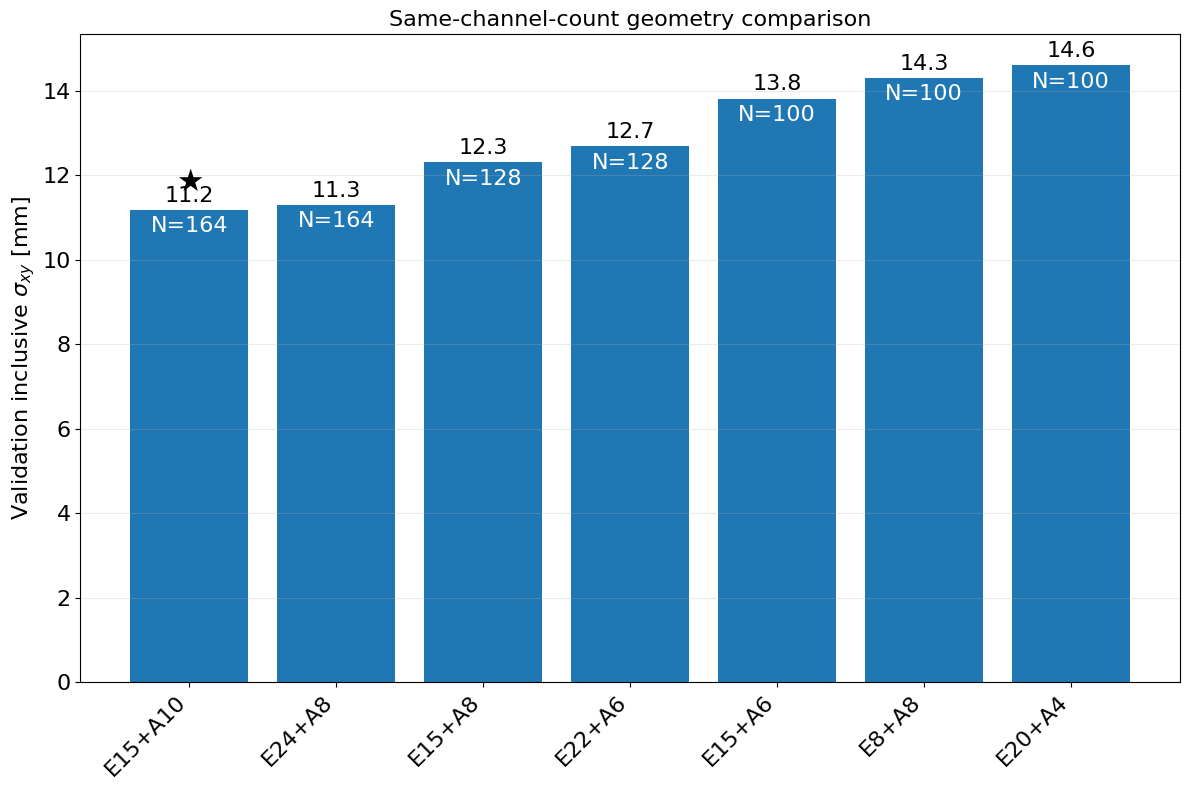

In [23]:
if not summary.empty:
    c = summary.total_channels.value_counts()
    sameN = summary[summary.total_channels.isin(c[c > 1].index)].copy()

    if not sameN.empty:
        sameN["setup"] = [f"E{int(e)}+A{int(a)}" for e,a in zip(sameN.edge, sameN["array"])]
        sameN = sameN.sort_values("sigma_xy_mm")

        fig, ax = plt.subplots(figsize=(12,8))
        x = np.arange(len(sameN))
        bars = ax.bar(x, sameN.sigma_xy_mm)

        ax.set_xticks(x, sameN.setup, rotation=45, ha="right")
        ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=16)

        for i, r in enumerate(sameN.itertuples()):
            ax.text(i, r.sigma_xy_mm-.15, f"N={int(r.total_channels)}",
                    ha="center", va="top", fontsize=16, color="white")

        # ★ best
        ax.text(0, sameN.sigma_xy_mm.iloc[0]+.45, "★",
                ha="center", fontsize=22)

        ax.set(ylabel=r"Validation inclusive $\sigma_{xy}$ [mm]",
               title="Same-channel-count geometry comparison")
        ax.tick_params(labelsize=16)
        plt.setp([ax.yaxis.label, ax.title], fontsize=16)
        ax.grid(axis="y", alpha=.25)

        plt.tight_layout()
        plt.savefig(OUT/"same_channel_count_comparison.png", dpi=180)
        plt.show()
    else:
        print("No repeated total-channel counts.")
else:
    print("No successful setups to display.")

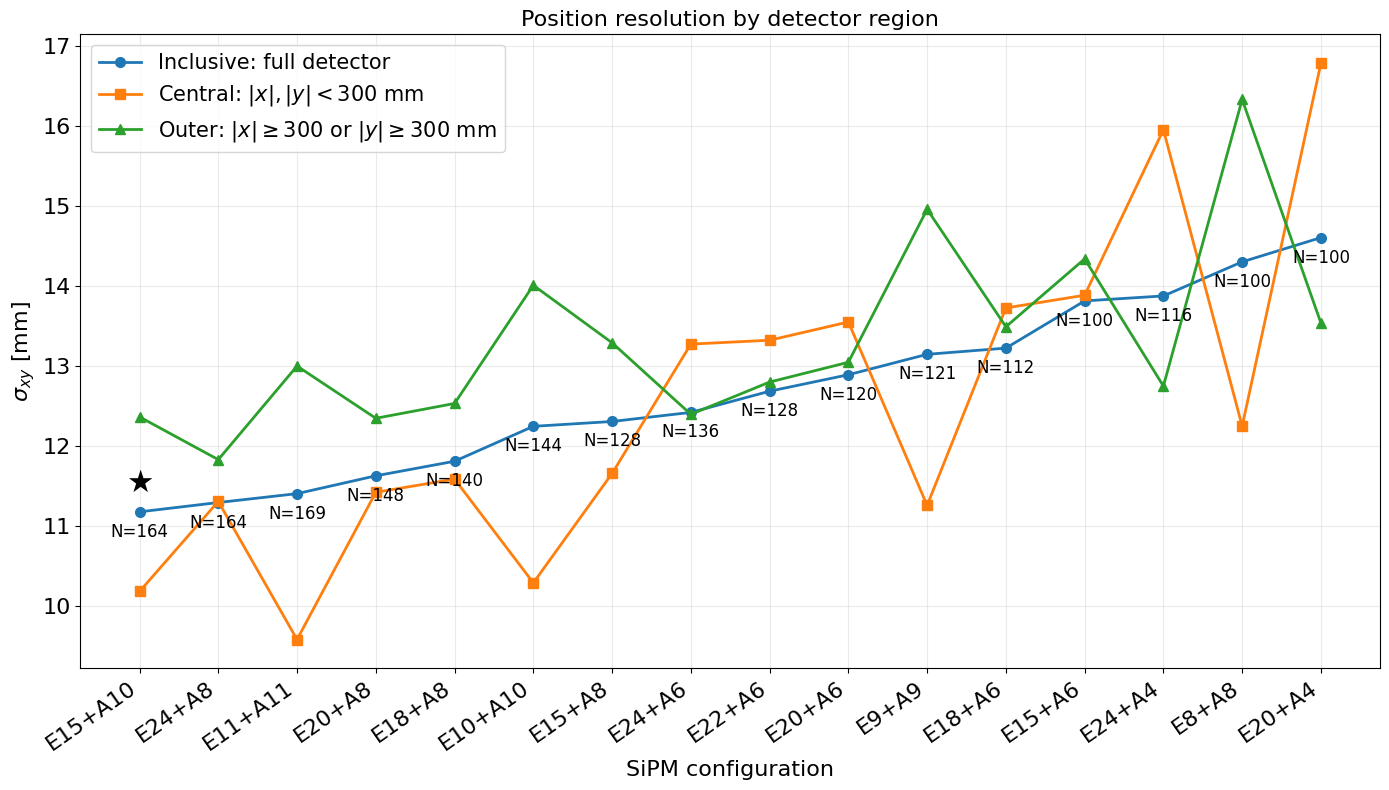

In [26]:
if not summary.empty:
    d = summary.sort_values("sigma_xy_mm").copy()
    d["setup"] = [f"E{int(e)}+A{int(a)}" for e,a in zip(d.edge,d["array"])]
    x = np.arange(len(d))

    fig, ax = plt.subplots(figsize=(14,8))

    ax.plot(x, d.sigma_xy_mm,        "o-", lw=2, ms=7, label="Inclusive: full detector")
    ax.plot(x, d.sigma_xy_center_mm, "s-", lw=2, ms=7, label=r"Central: $|x|,|y|<300$ mm")
    ax.plot(x, d.sigma_xy_outer_mm,  "^-", lw=2, ms=7, label=r"Outer: $|x|\geq300$ or $|y|\geq300$ mm")

    # Total channels close to inclusive points
    for i, r in enumerate(d.itertuples()):
        ax.annotate(f"N={int(r.total_channels)}",
                    (i, r.sigma_xy_mm),
                    xytext=(0, -18), textcoords="offset points",
                    ha="center", fontsize=12)

    ax.set(xticks=x, xticklabels=d.setup,
           xlabel="SiPM configuration",
           ylabel=r"$\sigma_{xy}$ [mm]",
           title="Position resolution by detector region")

    ax.tick_params(labelsize=16)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    plt.setp([ax.xaxis.label, ax.yaxis.label, ax.title], fontsize=16)

    # ★ best inclusive setup
    i = np.argmin(d.sigma_xy_mm.to_numpy())
    ax.text(i, d.sigma_xy_mm.iloc[i]+.25, "★",
            ha="center", fontsize=22)

    ax.legend(fontsize=15)
    ax.grid(alpha=.25)

    plt.tight_layout()
    plt.savefig(OUT/"inclusive_center_outer_comparison.png",
                dpi=180, bbox_inches="tight")
    plt.show()

else:
    print("No successful setups to display.")

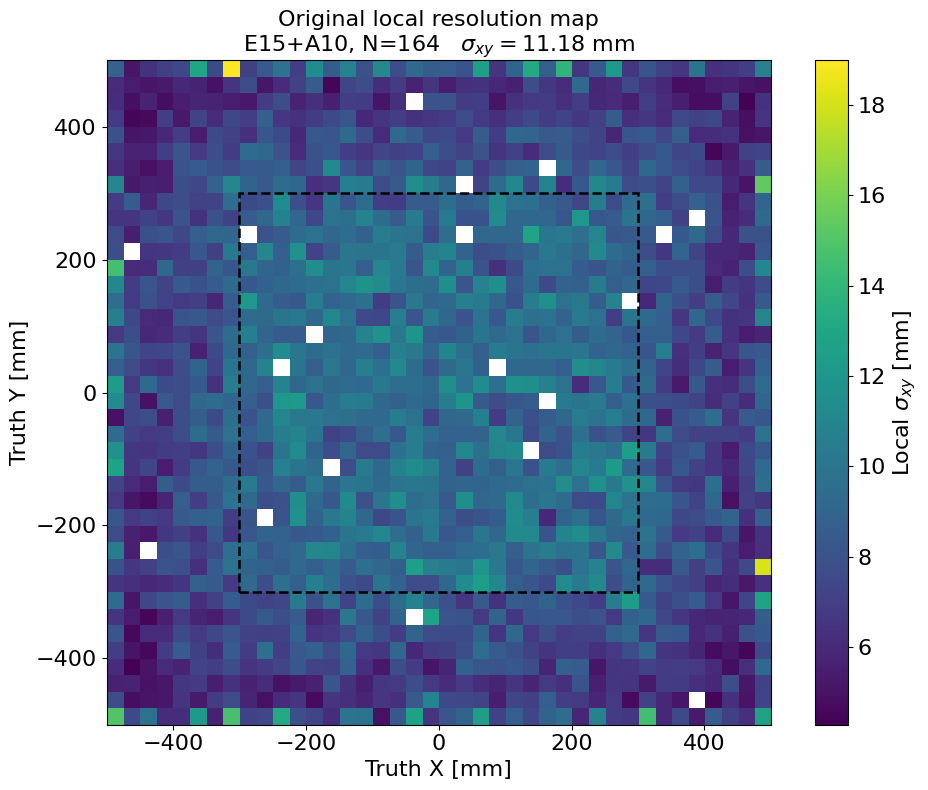

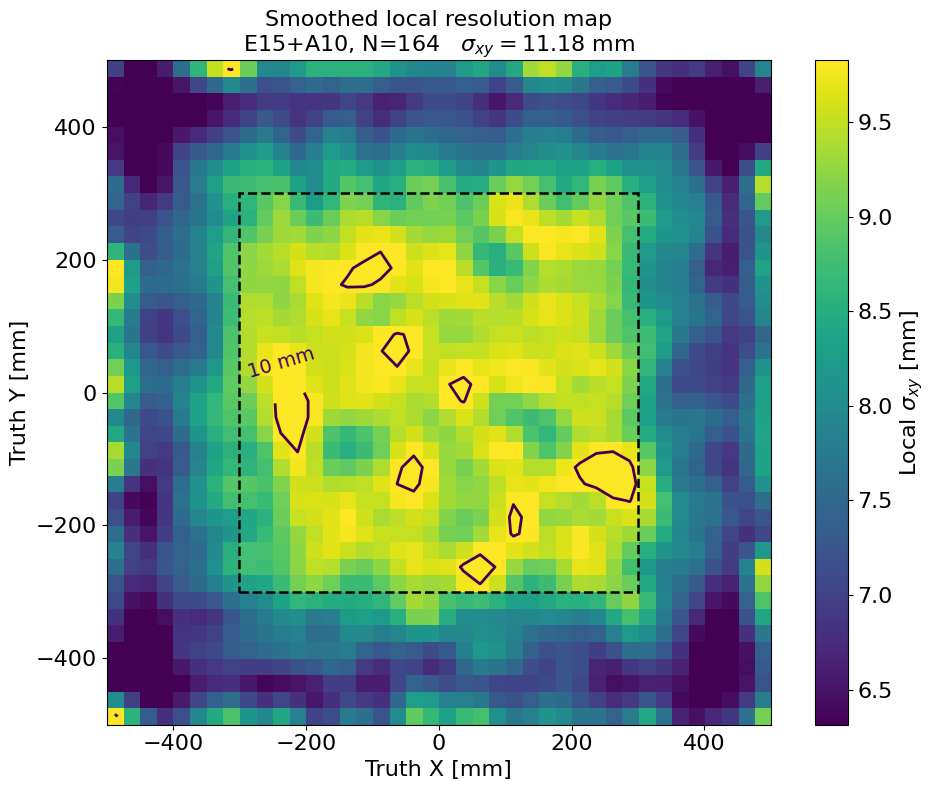

In [29]:
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Rectangle

if not summary.empty:
    r = summary.loc[summary.sigma_xy_mm.idxmin()]
    key = (int(r.edge), int(r["array"]))
    z = maps[key].copy()

    title = (f"E{key[0]}+A{key[1]}, N={int(r.total_channels)}   "
             rf"$\sigma_{{xy}}={r.sigma_xy_mm:.2f}$ mm")

    # --------------------------------------------------
    # 1. ORIGINAL resolution map
    # --------------------------------------------------
    fig, ax = plt.subplots(figsize=(10,8))
    im = ax.imshow(z, origin="lower",
                   extent=(-HALF,HALF,-HALF,HALF),
                   aspect="equal")

    ax.add_patch(Rectangle((-300,-300), 600,600, fill=False,
                           ls="--", lw=1.8))

    ax.set(xlabel="Truth X [mm]", ylabel="Truth Y [mm]",
           title="Original local resolution map\n"+title)
    ax.tick_params(labelsize=16)
    plt.setp([ax.xaxis.label, ax.yaxis.label, ax.title], fontsize=16)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label(r"Local $\sigma_{xy}$ [mm]", fontsize=16)
    cb.ax.tick_params(labelsize=16)

    plt.tight_layout()
    plt.savefig(OUT/"best_spatial_resolution_map_original.png",
                dpi=180, bbox_inches="tight")
    plt.show()


    # --------------------------------------------------
    # 2. SMOOTHED visualization
    # --------------------------------------------------
    good = np.isfinite(z)
    w  = gaussian_filter(good.astype(float), 1.0)
    zs = gaussian_filter(np.where(good,z,0), 1.0) / np.where(w>0,w,np.nan)

    vmin, vmax = np.nanpercentile(zs, [5,95])

    fig, ax = plt.subplots(figsize=(10,8))
    im = ax.imshow(zs, origin="lower",
                   extent=(-HALF,HALF,-HALF,HALF),
                   aspect="equal", vmin=vmin, vmax=vmax)

    c = np.linspace(-HALF+LENGTH/(2*MAP_GRID_N),
                     HALF-LENGTH/(2*MAP_GRID_N), MAP_GRID_N)
    X, Y = np.meshgrid(c,c)

    if np.nanmin(zs) < 10 < np.nanmax(zs):
        cs = ax.contour(X,Y,zs,levels=[10],linewidths=2)
        ax.clabel(cs, fmt={10:"10 mm"}, fontsize=14)

    ax.add_patch(Rectangle((-300,-300), 600,600, fill=False,
                           ls="--", lw=1.8))

    ax.set(xlabel="Truth X [mm]", ylabel="Truth Y [mm]",
           title="Smoothed local resolution map\n"+title)
    ax.tick_params(labelsize=16)
    plt.setp([ax.xaxis.label, ax.yaxis.label, ax.title], fontsize=16)

    cb = plt.colorbar(im, ax=ax)
    cb.set_label(r"Local $\sigma_{xy}$ [mm]", fontsize=16)
    cb.ax.tick_params(labelsize=16)

    plt.tight_layout()
    plt.savefig(OUT/"best_spatial_resolution_map_smoothed.png",
                dpi=180, bbox_inches="tight")
    plt.show()

## 14. Interpreting the detector comparison

Choose layouts using **validation** σxy, then inspect held-out `test_sigma_xy_mm`, bias,
coordinate RMSE, R68/R90, efficiency, center/outer sample sizes, and per-job variability.
The best of 16 validation scores has selection uncertainty; a single split is not an
uncertainty estimate. Small differences require independent-seed repeats or confidence
intervals before claiming a better detector. Source distributions and training budgets
must be comparable; small productions train on fewer events. Equal job counts do not
imply exactly equal event fractions. No matched-event pairing across layouts is assumed.

Local σxy maps subtract each bin's mean residual and can hide bias. Saved map archives
also contain coordinate RMSE, radial bias, occupancy, and bin edges. Sparse bins are
masked. These maps and reported resolutions describe selected detected events only.

Useful equal-channel comparisons remain: 100 channels (E20+A4, E15+A6, E8+A8),
128 channels (E22+A6, E15+A8), and 164 channels (E24+A8, E15+A10).
Each layout gets its own ExtraTrees model with the same fixed hyperparameters.

Methodology references: [scikit-learn leakage prevention](https://scikit-learn.org/stable/common_pitfalls.html)
and [group-based splits](https://scikit-learn.org/stable/modules/cross_validation.html#group-shuffle-split).
Training-only imputation was already present in the original; this revision preserves
it and adds masks, strict job holdouts, and separate validation-based layout selection.

**Validation of this corrected notebook:** syntax/schema checks and synthetic multi-file
ROOT regression tests are provided with the deliverable. A reduced-setting three-file
smoke run on the mounted Edge8+Array8 production completed, including training and
prediction. The full scan has not been rerun; no final detector resolution is claimed.
